# Tobacco Consumption Patterns

How are cigarette prices and recorded per-capita packs associated?

Data: [AER/CigarettesSW](https://vincentarelbundock.github.io/Rdatasets/doc/AER/CigarettesSW.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Repeated states and two historical periods; nominal prices and policy confound associations.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Tobacco Consumption Patterns',
 'executed_utc': '2026-11-21T10:14:15.442645+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/AER/CigarettesSW.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/AER/CigarettesSW.html',
 'sha256': '629e887a8104d483d450a9bbe487cb5613e62d116c4ecc84d6c8893b7393fcd2',
 'raw_rows': 96,
 'analysis_rows': 96,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8',
 'pearson': -0.6524731756886724,
 'spearman': -0.7316603364080304}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,96
1,state,object,0,0.0,48
2,year,int64,0,0.0,2
3,cpi,float64,0,0.0,2
4,population,int64,0,0.0,96
5,packs,float64,0,0.0,96
6,income,int64,0,0.0,96
7,tax,float64,0,0.0,58
8,price,float64,0,0.0,96
9,taxs,float64,0,0.0,93


## SQL and analysis
Complete-pair scatter plot of price and packs, with Pearson and Spearman correlations. No regression adjustment or causal claim.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "price" AS predictor, "packs" AS outcome FROM observations ORDER BY "price";

Among 96 complete observations, Pearson r = -0.652 and Spearman rho = -0.732.


,predictor,outcome
0,84.967995,155.283768
1,87.001251,186.035187
2,90.641251,127.209442
3,91.615334,134.009796
4,91.966667,120.978706
5,93.466667,129.399994
6,94.266663,112.963539
7,95.500000,197.993988
8,96.180000,137.637375
9,97.025169,127.234619


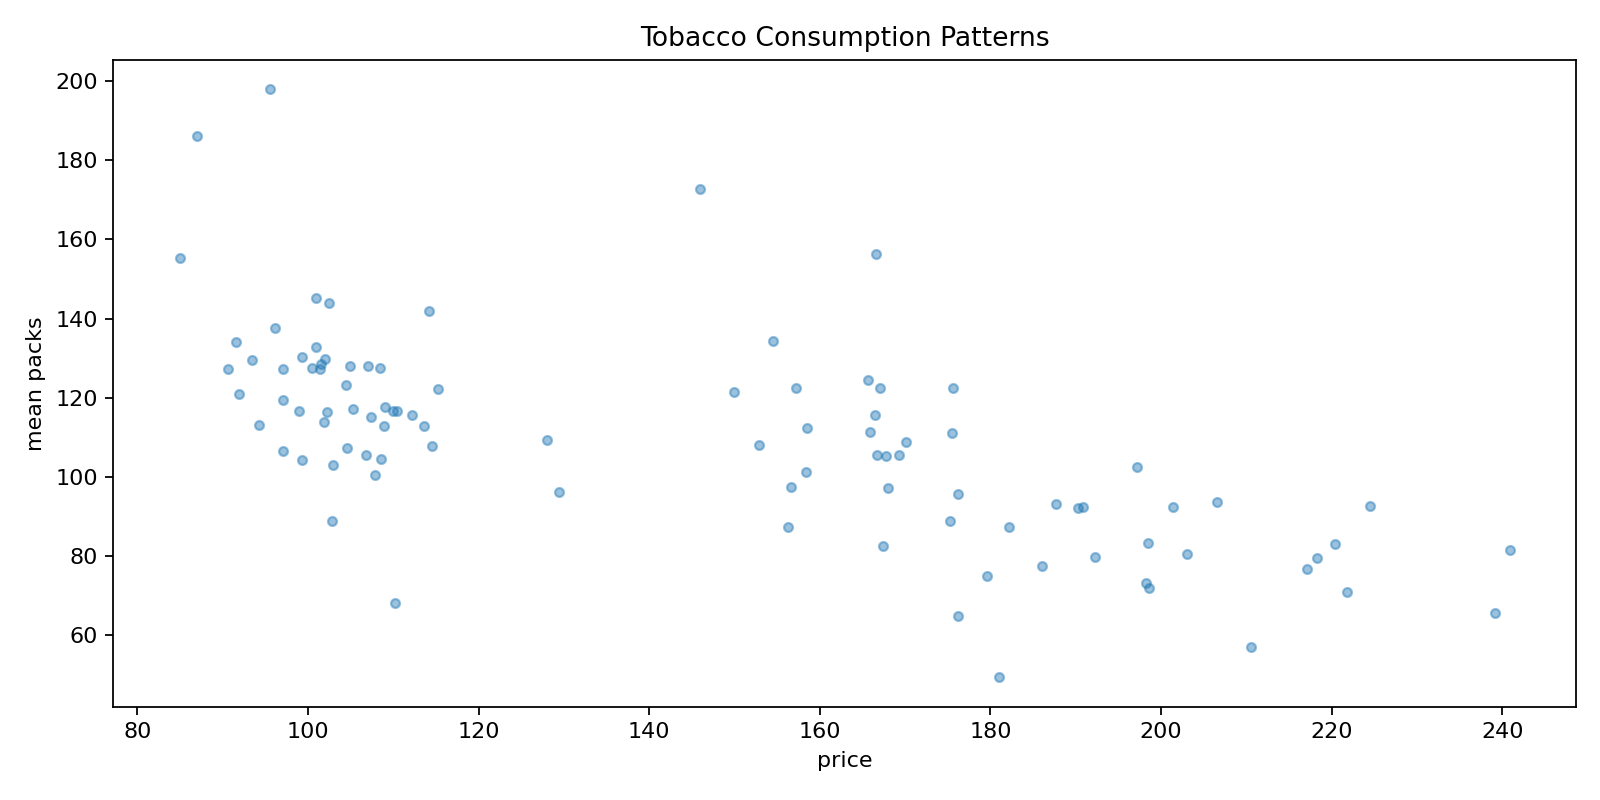

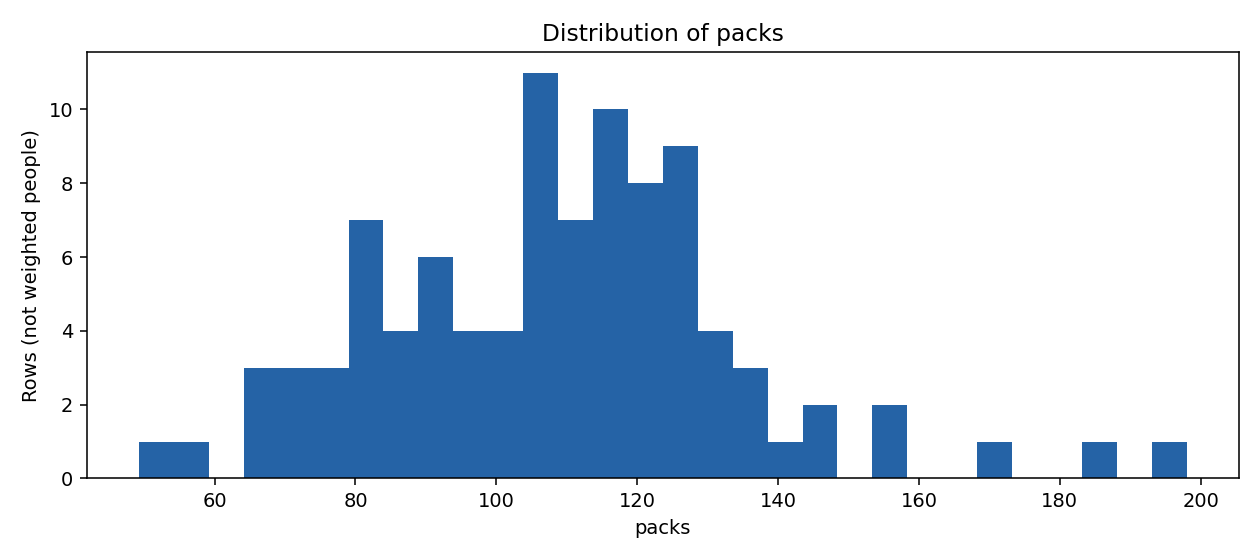

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Repeated states and two historical periods; nominal prices and policy confound associations.

**Next action:** Deflate prices and use a panel design before estimating elasticities.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.